# 3 · Data Preparation — shared split, loader and conventions

**CRISP-DM phase 3.** Previous: [`2_Data_Understanding.ipynb`](2_Data_Understanding.ipynb) · Next: [`4_Modeling/`](4_Modeling/)

What this notebook prepares for the three binômes:
1. **The frozen train / validation / test split** (`splits/split_manifest.csv`). It is **checked, never rewritten**: the documented procedure is run again and must give back exactly the same split.
2. **Split statistics** and the normal data available to the autoencoder in the train split.
3. **The shared DataLoader** (`roadanomaly.data_pipeline`): resizing, mask convention, augmentation.
4. **Normalisation conventions** and what each binôme reuses.

The test split is never loaded here: only its file names and statistics from the full-resolution masks are used, as when the split was made.

## TL;DR — one sealed envelope, one loader, one floor

Think of a fair exam: everyone sits it on the same day, with the same paper, and nobody sees the questions in advance. This notebook builds that fairness for the three binômes.

- **The sealed envelope (§1).** The 60 photographs are split 42 train / 9 validation / 9 test. The split is rebuilt from the raw files on every run (the best of 500 seeded candidates) and must come out **identical** to `splits/split_manifest.csv`, or the notebook stops. The test photographs are never loaded here; they are opened once, in notebook 5.
- **Same difficulty in every split (§2).** Each split keeps a median of about 7 % obstacle pixels. The test split holds **22 obstacles** and no lost-tyre scene; validation holds 37 (36 once resized to 352×640, where one of them falls under the 4-px speckle limit).
- **One loader for everyone (§4).** Images in [0, 1] at 352×640, binary masks, and the same training augmentation (horizontal flip, crop of at least 80 %, brightness and contrast). If two models differ, it is because of the model, not the data feeding.
- **The floor (§6).** Flagging every pixel as obstacle scores F1 **0.159** on validation, and a random score map scores AuPRC **0.0907**. A model is only interesting above these numbers.
- **Normal data for the autoencoders (§3).** 5,325 obstacle-free 64×64 tiles in the training photos, counted with the same code the autoencoders use.

## 0. Setup

In [1]:
# Import libraries
import os
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "3")   # hide TensorFlow C++ log lines (e.g. the harmless "use_unbounded_threadpool" notice)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

import keras
import tensorflow as tf
tf.get_logger().setLevel("ERROR")                    # hide tf.function retracing notices

from roadanomaly import data_pipeline as dp, evaluation, splitting
from roadanomaly.gpu import setup_gpu
from roadanomaly.normal_regions import MASK_MARGIN, normal_patches
from roadanomaly.protocol import IMG_SIZE, SEED

import warnings
warnings.filterwarnings('ignore')

FIG_DIR = dp.FIG_DIR
keras.utils.set_random_seed(SEED)
GPU_NAME = setup_gpu()
print("TensorFlow:", tf.__version__, "| IMG_SIZE:", IMG_SIZE)

GPU: NVIDIA GeForce RTX 4060 Laptop GPU | compute capability: (8, 9)
TensorFlow: 2.20.0 | IMG_SIZE: (352, 640)


## 1. The frozen split: rebuild it and check it
How the split is made (`roadanomaly.splitting`):
- **Group-aware:** a scene group (notebook 2, section 8) never spans two splits.
- **Stratified by category:** validation and test get at least one image of every category that has enough independent groups.
- Target about 70 / 15 / 15: with 60 images this leaves 9 images each for validation and test.
- **Representative:** 500 seeded candidate splits are generated, and the one whose validation and test sets are closest to the whole dataset (anomaly ratio and number of objects per image) is kept.
- **The test split is frozen:** it is used once, in notebook 5, for the final comparison of the three approaches. Thresholds, early stopping and model selection use validation only.

The cell below runs this procedure again from the raw data and **asserts that it gives the saved manifest exactly**. Nothing is written: the manifest is the reference of the whole project.

In [2]:
# Rebuild the split from the raw data with the documented procedure
stats_df = splitting.frame_statistics()
stats_df["scene_group"] = stats_df["frame"].map(
    splitting.scene_groups(stats_df["frame"].tolist(), dp.DATA_DIR / "credits.txt"))
rebuilt, best_seed, best_distance = splitting.best_split(stats_df)
print(f"Best of {len(splitting.SPLIT_SEEDS)} candidate splits: seed {best_seed}, distance {best_distance:.3f}")

# The saved manifest: sizes, unique frames, no scene group in two splits
manifest = splitting.verify_manifest().set_index("frame")
same = (rebuilt.values == manifest.loc[stats_df["frame"], "split"].values)
assert same.all(), f"the procedure does not give the saved manifest for {list(stats_df['frame'][~same])}"
stats_df["split"] = rebuilt.values
print("The rebuilt split is identical to splits/split_manifest.csv (60 / 60 frames)")
print(stats_df["split"].value_counts().to_string())

Best of 500 candidate splits: seed 415, distance 0.340
The rebuilt split is identical to splits/split_manifest.csv (60 / 60 frames)
split
train    42
val       9
test      9


## 2. Statistics per split

In [3]:
# Statistics per split: categories, anomaly ratio, number of objects
print(pd.crosstab(stats_df["category"], stats_df["split"]).to_string())
print()
summary = stats_df.groupby("split").agg(images=("frame", "count"),
                                        median_anomaly_ratio=("anomaly_ratio", "median"),
                                        min_anomaly_ratio=("anomaly_ratio", "min"),
                                        max_anomaly_ratio=("anomaly_ratio", "max"),
                                        mean_objects=("n_objects", "mean"),
                                        objects=("n_objects", "sum"))
print(summary.round(4).to_string())
print("\nWhole dataset: median anomaly ratio", round(stats_df["anomaly_ratio"].median(), 4),
      "| mean objects per image", round(stats_df["n_objects"].mean(), 2))

split       test  train  val
category                    
animals        5     21    5
cones          1      6    1
lost_tires     0      3    0
obstacles      2     11    2
vehicle        1      1    1

       images  median_anomaly_ratio  min_anomaly_ratio  max_anomaly_ratio  mean_objects  objects
split                                                                                           
test        9                0.0703             0.0162             0.1905        2.4444       22
train      42                0.0644             0.0037             0.4233        4.2857      180
val         9                0.0664             0.0135             0.2468        4.1111       37

Whole dataset: median anomaly ratio 0.0662 | mean objects per image 3.98


## 3. Normal data for the autoencoder (train split only)
Binôme B learns "normal road" from the background of the **train** images only. Two counts: without margin (pure anomaly-free patches) and with the `MASK_MARGIN` used in training (each obstacle dilated by a few pixels, because annotation borders are loose). `roadanomaly.normal_regions` is the code used by the autoencoders themselves.

In [4]:
# Anomaly-free patches available for the autoencoder in the final TRAIN split only
_, x_train, y_train = dp.load_split("train", IMG_SIZE)
rows = []
for patch in [64, 128]:
    for margin in [0, MASK_MARGIN]:
        patches, total = normal_patches(x_train, y_train, patch=patch, stride=patch // 2, margin=margin)
        rows.append({"patch": f"{patch}x{patch}", "stride": patch // 2, "obstacle margin (px)": margin,
                     "candidates": total, "normal": len(patches), "% normal": round(100 * len(patches) / total, 1)})
pd.DataFrame(rows)

,patch,stride,obstacle margin (px),candidates,normal,% normal
0,64x64,32,0,7980,5488,68.8
1,64x64,32,4,7980,5325,66.7
2,128x128,64,0,1512,740,48.9
3,128x128,64,4,1512,715,47.3


## 4. Shared DataLoader
`roadanomaly.data_pipeline` loads each split into memory (60 images), resizes the image (bilinear) and the mask (nearest, so it stays binary) to `IMG_SIZE`, and builds a `tf.data` pipeline. Only training batches are augmented, and the geometric part of the augmentation (horizontal flip, random crop of at least 80 %) is applied to the image and the mask together. Brightness and contrast jitter touch the image only. There is no vertical flip: the road is always at the bottom (notebook 2, section 6).

In [5]:
# Load the splits at the working resolution
BATCH_SIZE = 8

val_frames, x_val, y_val = dp.load_split("val", IMG_SIZE)
print("x_train:", x_train.shape, x_train.dtype, "range", (float(x_train.min()), float(x_train.max())))
print("y_train:", y_train.shape, y_train.dtype, "values", np.unique(y_train))
print("x_val  :", x_val.shape)
print("y_val  :", y_val.shape)

train_dataset = dp.get_dataset(x_train, y_train, BATCH_SIZE, training=True, seed=SEED)
valid_dataset = dp.get_dataset(x_val, y_val, BATCH_SIZE)

x_train: (42, 352, 640, 3) float32 range (0.0, 1.0)
y_train: (42, 352, 640, 1) float32 values [0. 1.]
x_val  : (9, 352, 640, 3)
y_val  : (9, 352, 640, 1)


I0000 00:00:1793563077.344705 2498021 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 6249 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 4060 Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.9


batch images: (8, 352, 640, 3) | batch masks: (8, 352, 640, 1) | mask values: [0. 1.]


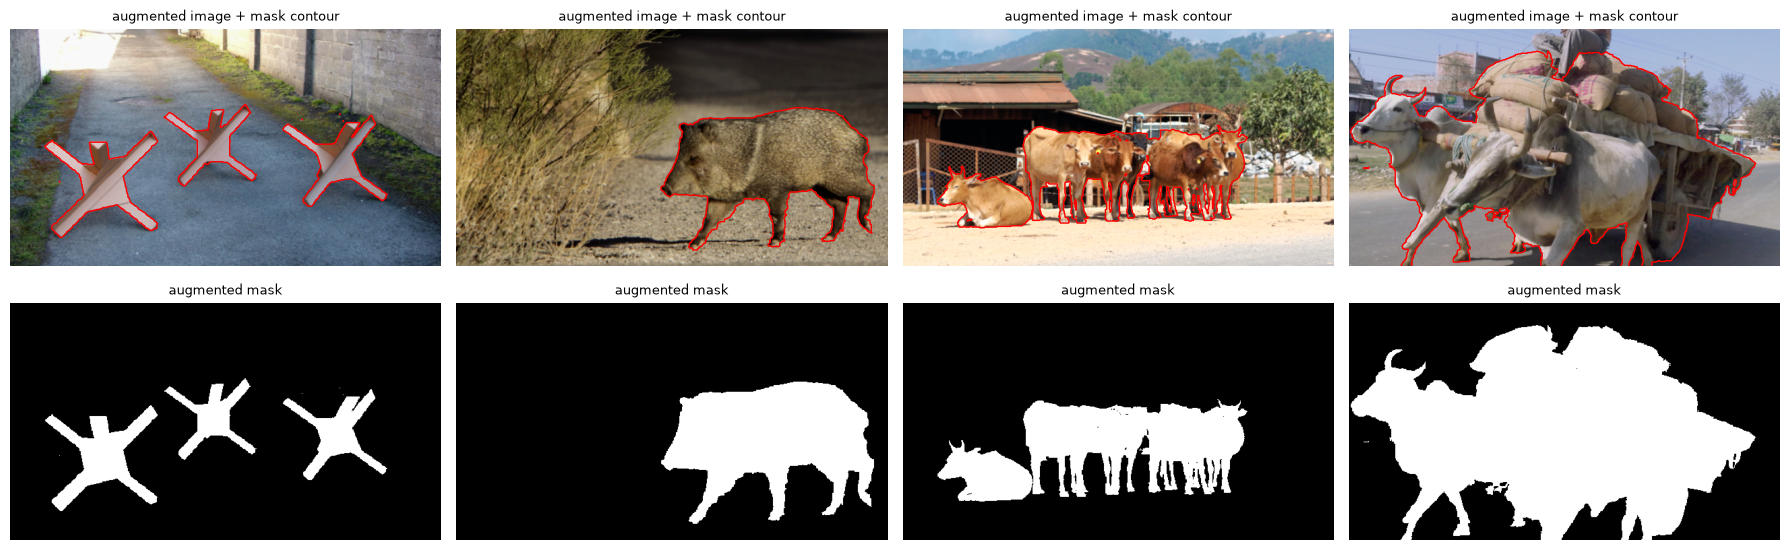

Input batch in memory: 29 MB (the rest of the 6 GB budget is for the model and its activations)


In [6]:
# One augmented training batch: the mask contour must sit on the object after augmentation
images, masks = next(iter(train_dataset))
print("batch images:", images.shape, "| batch masks:", masks.shape, "| mask values:", np.unique(masks.numpy()))
assert set(np.unique(masks.numpy())) <= {0.0, 1.0}

fig, ax = plt.subplots(2, 4, figsize=(18, 6), tight_layout=True)
for i in range(4):
    ax[0, i].imshow(images[i])
    ax[0, i].contour(masks[i, ..., 0], levels=[0.5], colors="red", linewidths=1)
    ax[0, i].set_title("augmented image + mask contour", fontsize=9)
    ax[1, i].imshow(masks[i, ..., 0], cmap="gray")
    ax[1, i].set_title("augmented mask", fontsize=9)
    ax[0, i].axis("off"); ax[1, i].axis("off")
plt.savefig(FIG_DIR / "07_augmented_batch.png", dpi=70)
plt.show()

batch_mb = BATCH_SIZE * IMG_SIZE[0] * IMG_SIZE[1] * 4 * 4 / 1e6
print(f"Input batch in memory: {batch_mb:.0f} MB (the rest of the 6 GB budget is for the model and its activations)")

## 5. Normalisation conventions
| Stage | Convention | Where |
|---|---|---|
| Loader output | RGB float32 in **[0, 1]**, masks float32 {0, 1} of shape (H, W, 1) | `data_pipeline.load_split` |
| Pretrained backbones (A: ResNet50; B: VGG16, and VGG19 in the pixel AE's perceptual loss; C: ResNet50 of the pretrained U-Net) | each backbone's own `preprocess_input` on 0–255 images, applied **inside** the model, the loss or the feature extractor | `models/deeplabv3plus.py`, `models/feature_ae.py`, `models/unet.py` |
| Feature autoencoder (B) | per-channel z-score with the mean / std of the **train** normal cells only | `models/feature_ae.feature_statistics` |
| Score maps of autoencoders | Gaussian smoothing + per-image z-score, settings chosen on validation | `postprocessing.anomaly_scores` |

Every statistic is fitted on the train split; validation and test only reuse it.

## 6. The floor every model must beat
What trivial predictors score on the validation split, computed with the shared evaluation code. The metric functions themselves are checked against hand-computed cases in `tests/test_metrics_and_postprocessing.py` (`mise run test`).

In [7]:
# Trivial predictors on validation: per-image mean scores
_, x_val, y_val = dp.load_split("val", IMG_SIZE)
gt_val = y_val[..., 0].astype(bool)
print(pd.DataFrame(evaluation.trivial_baselines(gt_val)).T.round(3).to_string())
print(f"\nAuPRC chance level on val = anomaly pixel prevalence = {gt_val.mean():.4f} (AUROC chance is always 0.5)")

                precision  recall     f1    iou   dice
all background      0.000     0.0  0.000  0.000  0.000
all anomaly         0.091     1.0  0.159  0.091  0.159

AuPRC chance level on val = anomaly pixel prevalence = 0.0907 (AUROC chance is always 0.5)


## 7. What each binôme reuses
```python
from roadanomaly import data_pipeline as dp, evaluation, postprocessing
from roadanomaly.protocol import IMG_SIZE, SEED, MIN_OBJECT_PX
from roadanomaly.inference import save_artifact          # the shared model format (README, rule 2)
from roadanomaly.gpu import setup_gpu

setup_gpu(mixed_precision=True)     # float16 works on RTX 4060 and RTX 2060 (no bfloat16)
_, x_train, y_train = dp.load_split("train", IMG_SIZE)
_, x_val, y_val = dp.load_split("val", IMG_SIZE)          # the test split is loaded only in notebook 5
train_dataset = dp.get_dataset(x_train, y_train, BATCH_SIZE, training=True)
valid_dataset = dp.get_dataset(x_val, y_val, BATCH_SIZE)
# model.compile(..., jit_compile=False)  # TF 2.20 XLA fails with mixed precision on some graphs
```

| Binôme | Model | Training batch | Notes |
|---|---|---|---|
| A: Ines & Emna | DeepLabV3+ with transfer learning | 2 (Ines's setting; 4 fits in 6 GB) | Backbone `preprocess_input` **inside** the model (the loader returns [0, 1]). Binary labels, so mIoU reduces to 2 classes. Saves `models/A_deeplabv3plus/`. |
| B: Khaled & Adrian | Convolutional autoencoder (pixel baseline + feature-space AE) | 64 patches (pixel AE), 8 feature maps (feature AE) | Trains on normal regions of the **train** split (`normal_regions`). Error-map threshold on validation. AuPRC, AUROC and AUPRO. Saves `models/B_pixel_ae/` and `models/B_feature_ae/`. |
| C: Hejer & Walid | CNN baseline + U-Nets | 4 (CNN, U-Net), 8 (U-Net ResNet50, 4.6 GB peak) | ImageNet preprocessing **inside** the pretrained U-Net. HD95 on masks filtered with `remove_small_components`, in px at 352x640. Saves `models/C_cnn/`, `models/C_unet/` and `models/C_unet_resnet50/`. |